# At Yarışı Sonuç Sıralaması Tahmini (Learning-to-Rank)

**Problem:** Bir yarışa katılan atların yarış öncesi bilinen bilgilerinden (at, jokey, antrenör, kilo,
kulvar, handikap puanı, pist koşulları, ganyan oranı ve geçmiş performans) yola çıkarak **bitiş
sıralamasını** tahmin etmek.

**Veri:** Kaggle – *Horse Racing in HK* (Hong Kong Jockey Club, 1997–2005)
https://www.kaggle.com/datasets/gdaley/hkracing — `races.csv` ve `runs.csv`

**Yaklaşım:** Problem bir *sıralama (learning-to-rank)* problemi olarak ele alınır. Temel modeller
(piyasa favorisi, Logistic Regression, Random Forest) ile LightGBM **LambdaRank** karşılaştırılır.
Eğitim/doğrulama/test ayrımı **zamana göre** yapılır; böylece model yalnızca geçmişten öğrenip
geleceği tahmin eder (veri sızıntısı yok).

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, ndcg_score, precision_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = os.environ.get("DATA_DIR", "data")
FIG_DIR = os.environ.get("FIG_DIR", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
RANDOM_STATE = 42


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight", dpi=150)
    plt.show()

## 1. Veri Setinin Yüklenmesi ve Tanıtılması
- `races.csv`: her satır bir yarış (tarih, hipodrom, mesafe, pist türü, pist durumu, sınıf, ödül...)
- `runs.csv`: her satır bir atın bir yarıştaki koşusu (at, jokey, antrenör, kilo, kulvar, oran, sonuç...)

In [2]:
races = pd.read_csv(os.path.join(DATA_DIR, "races.csv"))
runs = pd.read_csv(os.path.join(DATA_DIR, "runs.csv"))
print("races:", races.shape, "| runs:", runs.shape)
races["date"] = pd.to_datetime(races["date"])
print("Tarih aralığı:", races["date"].min().date(), "→", races["date"].max().date())
runs.head()

races: (6349, 37) | runs: (79447, 37)
Tarih aralığı: 1997-06-02 → 2005-08-28


,race_id,horse_no,horse_id,result,won,lengths_behind,horse_age,horse_country,horse_type,horse_rating,horse_gear,declared_weight,actual_weight,draw,position_sec1,position_sec2,position_sec3,position_sec4,position_sec5,position_sec6,behind_sec1,behind_sec2,behind_sec3,behind_sec4,behind_sec5,behind_sec6,time1,time2,time3,time4,time5,time6,finish_time,win_odds,place_odds,trainer_id,jockey_id
0,0,1,3917,10,0.0,8.00,3,AUS,Gelding,60,--,1020.0,133,7,6,4,6,10.0,NaN,NaN,2.00,2.00,1.50,8.00,NaN,NaN,13.85,21.59,23.86,24.62,NaN,NaN,83.92,9.7,3.7,118,2
1,0,2,2157,8,0.0,5.75,3,NZ,Gelding,60,--,980.0,133,12,12,13,13,8.0,NaN,NaN,6.50,9.00,5.00,5.75,NaN,NaN,14.57,21.99,23.30,23.70,NaN,NaN,83.56,16.0,4.9,164,57
2,0,3,858,7,0.0,4.75,3,NZ,Gelding,60,--,1082.0,132,8,3,2,2,7.0,NaN,NaN,1.00,1.00,0.75,4.75,NaN,NaN,13.69,21.59,23.90,24.22,NaN,NaN,83.40,3.5,1.5,137,18
3,0,4,1853,9,0.0,6.25,3,SAF,Gelding,60,--,1118.0,127,13,8,8,11,9.0,NaN,NaN,3.50,5.00,3.50,6.25,NaN,NaN,14.09,21.83,23.70,24.00,NaN,NaN,83.62,39.0,11.0,80,59
4,0,5,2796,6,0.0,3.75,3,GB,Gelding,60,--,972.0,131,14,13,12,12,6.0,NaN,NaN,7.75,8.75,4.25,3.75,NaN,NaN,14.77,21.75,23.22,23.50,NaN,NaN,83.24,50.0,14.0,9,154


In [3]:
race_cols = ["race_id", "date", "venue", "race_no", "config", "surface", "distance", "going",
             "race_class", "prize"]
df = runs.merge(races[race_cols], on="race_id", how="left")
print("Birleştirilmiş veri:", df.shape)
print("\nEksik değer oranları (%):")
print((df.isna().mean() * 100).round(2).loc[lambda s: s > 0].sort_values(ascending=False))

Birleştirilmiş veri: (79447, 46)

Eksik değer oranları (%):
position_sec6    98.37
behind_sec6      98.37
time6            98.37
position_sec5    87.31
behind_sec5      87.31
time5            87.31
position_sec4    41.82
behind_sec4      41.82
time4            41.82
prize             7.36
place_odds        4.70
dtype: float64


## 2. Veri Temizleme
- Sonucu geçersiz (yarışı bitirmemiş / 0) olan koşular çıkarılır.
- Yarış sırasında oluşan bilgiler (`position_sec*`, `behind_sec*`, `time*`, `finish_time`,
  `lengths_behind`) **yarış öncesinde bilinmediği için** modele verilmez (veri sızıntısını önlemek için).
- Kategorik eksikler "Unknown" ile doldurulur.

In [4]:
df = df[df["result"].between(1, 14)].copy()
df["field_size"] = df.groupby("race_id")["horse_id"].transform("size")
df = df[df["field_size"] >= 4]
df["result"] = df.groupby("race_id")["result"].rank(method="first").astype(int)  # 1..N sıralı
df["won"] = (df["result"] == 1).astype(int)

for c in ["horse_country", "horse_type", "horse_gear", "going", "config", "venue"]:
    df[c] = df[c].fillna("Unknown").astype(str)
df["prize"] = df["prize"].fillna(df["prize"].median())
df["win_odds"] = df["win_odds"].clip(lower=1.0, upper=99.0)

df = df.sort_values(["date", "race_no", "race_id", "horse_no"]).reset_index(drop=True)
print("Temiz veri:", df.shape, "| yarış sayısı:", df["race_id"].nunique(),
      "| at:", df["horse_id"].nunique(), "| jokey:", df["jockey_id"].nunique())

Temiz veri: (79447, 47) | yarış sayısı: 6348 | at: 4405 | jokey: 186


## 3. Veri Keşfi (EDA)

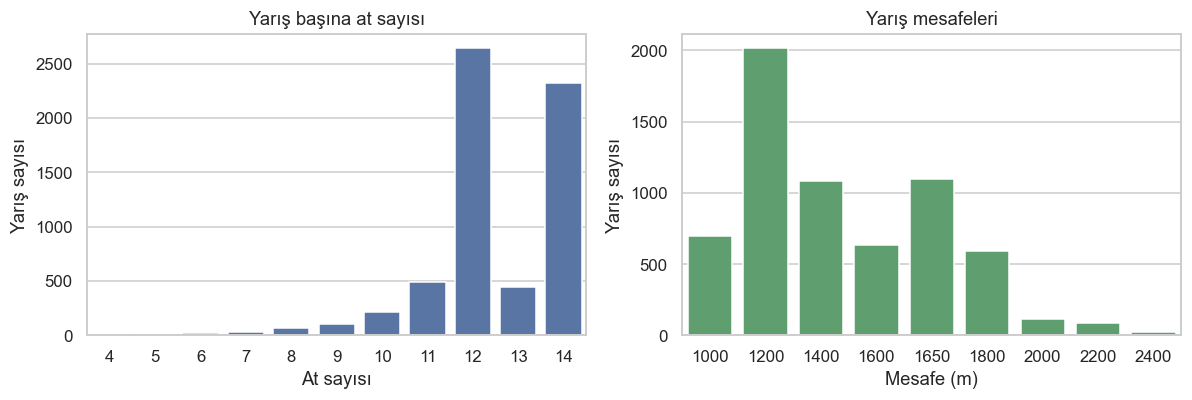

Rastgele bir atın kazanma olasılığı ≈ %8.0 → sınıf dengesizliği (1 kazanan / ~12 at)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
fs = df.drop_duplicates("race_id")["field_size"]
sns.countplot(x=fs, ax=axes[0], color="#4C72B0")
axes[0].set(title="Yarış başına at sayısı", xlabel="At sayısı", ylabel="Yarış sayısı")
win_share = df["won"].mean() * 100
sns.countplot(x=df.drop_duplicates("race_id")["distance"], ax=axes[1], color="#55A868")
axes[1].set(title="Yarış mesafeleri", xlabel="Mesafe (m)", ylabel="Yarış sayısı")
savefig("eda_field_distance")
print(f"Rastgele bir atın kazanma olasılığı ≈ %{win_share:.1f} → sınıf dengesizliği (1 kazanan / ~12 at)")

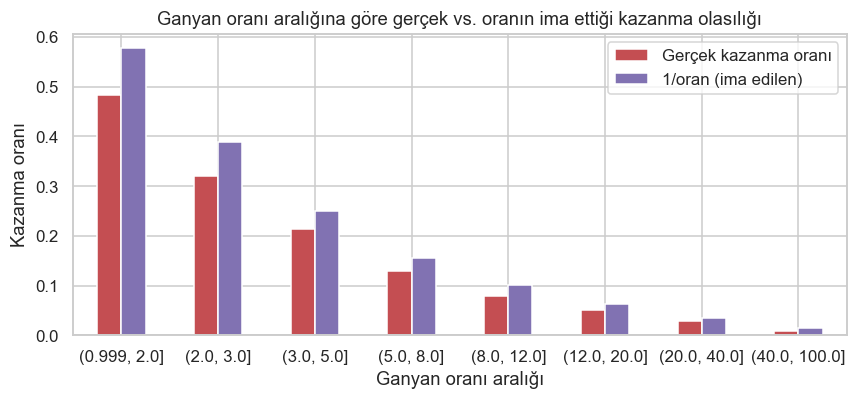

In [6]:
# Gözlem 1: Ganyan oranı (piyasa beklentisi) ile kazanma oranı ilişkisi
bins = [1, 2, 3, 5, 8, 12, 20, 40, 100]
df["odds_bucket"] = pd.cut(df["win_odds"], bins=bins, include_lowest=True)
g = df.groupby("odds_bucket", observed=True).agg(gercek=("won", "mean"),
                                                  ima=("win_odds", lambda s: (1 / s).mean()))
ax = g.plot(kind="bar", figsize=(8, 3.8), color=["#C44E52", "#8172B2"])
ax.set(title="Ganyan oranı aralığına göre gerçek vs. oranın ima ettiği kazanma olasılığı",
       xlabel="Ganyan oranı aralığı", ylabel="Kazanma oranı")
ax.legend(["Gerçek kazanma oranı", "1/oran (ima edilen)"])
plt.xticks(rotation=0)
savefig("eda_odds_calibration")

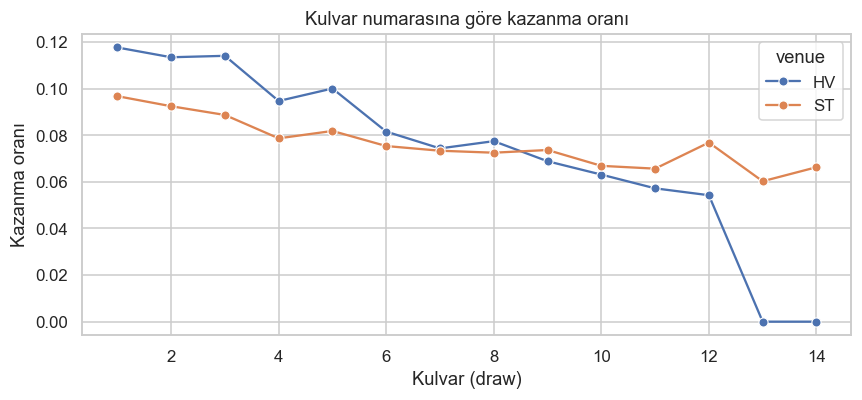

In [7]:
# Gözlem 2: Kulvar (draw) etkisi – hipodrom ve pist türüne göre
d = df[df["draw"].between(1, 14)]
g = d.groupby(["venue", "draw"])["won"].mean().reset_index()
plt.figure(figsize=(8, 3.8))
sns.lineplot(data=g, x="draw", y="won", hue="venue", marker="o")
plt.title("Kulvar numarasına göre kazanma oranı")
plt.xlabel("Kulvar (draw)"); plt.ylabel("Kazanma oranı")
savefig("eda_draw")

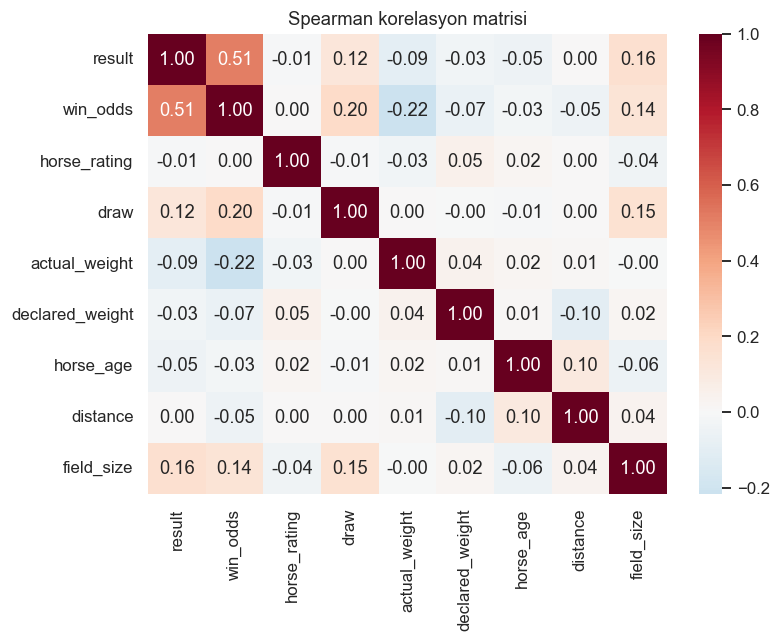

In [8]:
# Gözlem 3: Sayısal değişkenlerin bitiş sırası ile korelasyonu
num_cols = ["result", "win_odds", "horse_rating", "draw", "actual_weight", "declared_weight",
            "horse_age", "distance", "field_size"]
plt.figure(figsize=(7.5, 6))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Spearman korelasyon matrisi")
savefig("eda_corr")

## 4. Özellik Mühendisliği
Yalnızca **yarıştan önce bilinen** bilgiler kullanılır:
1. **Geçmiş performans** (at / jokey / antrenör): her koşu için sadece *daha önceki* yarışlar
   kullanılarak hesaplanan kazanma oranı, ortalama normalize bitiş yeri, son yarış sonucu,
   son yarıştan bu yana geçen gün vb. (`shift` ile sızıntı engellenir).
2. **Yarış içi göreli özellikler:** sıralama bir *yarış içi karşılaştırma* olduğundan, atın
   rakiplerine göre durumu (puan farkı, oran sırası, piyasa olasılığı payı) hesaplanır.
3. **Ekipman:** `horse_gear` alanından ekipman kullanımı / sayısı.

In [9]:
df["norm_pos"] = (df["result"] - 1) / (df["field_size"] - 1)  # 0 = birinci, 1 = sonuncu
df["top3"] = (df["result"] <= 3).astype(int)


def history_features(frame, key, prefix, m=20):
    """Bir varlığın (at/jokey/antrenör) yalnızca önceki koşularından hesaplanan özellikler."""
    g = frame.groupby(key)
    n_prev = g.cumcount()
    wins_prev = g["won"].cumsum() - frame["won"]
    top3_prev = g["top3"].cumsum() - frame["top3"]
    pos_prev = g["norm_pos"].cumsum() - frame["norm_pos"]
    glob_win, glob_top3 = frame["won"].mean(), frame["top3"].mean()
    out = pd.DataFrame(index=frame.index)
    out[f"{prefix}_n_runs"] = n_prev
    # Bayesyen düzeltme: az koşusu olanlar genel ortalamaya çekilir
    out[f"{prefix}_win_rate"] = (wins_prev + m * glob_win) / (n_prev + m)
    out[f"{prefix}_top3_rate"] = (top3_prev + m * glob_top3) / (n_prev + m)
    out[f"{prefix}_avg_pos"] = (pos_prev + m * 0.5) / (n_prev + m)
    return out


# Aynı gün içindeki yarışlar race_no sırasıyla zaten kronolojik
df = pd.concat([df,
                history_features(df, "horse_id", "horse", m=3),
                history_features(df, "jockey_id", "jockey", m=50),
                history_features(df, "trainer_id", "trainer", m=50)], axis=1)

gh = df.groupby("horse_id")
df["horse_last_pos"] = gh["norm_pos"].shift(1).fillna(0.5)
df["horse_last2_pos"] = gh["norm_pos"].shift(2).fillna(0.5)
df["days_since_last"] = gh["date"].diff().dt.days.fillna(60).clip(upper=365)
df["rating_change"] = gh["horse_rating"].diff().fillna(0)
df["weight_change"] = gh["declared_weight"].diff().fillna(0)
df["same_dist_prev"] = (gh["distance"].shift(1) == df["distance"]).astype(int)

# Ekipman
df["has_gear"] = (df["horse_gear"] != "--").astype(int)
df["n_gear"] = df["horse_gear"].apply(lambda s: 0 if s in ("--", "Unknown") else len(s.split("/")))

# Yarış içi göreli özellikler
gr = df.groupby("race_id")
df["implied_prob"] = 1 / df["win_odds"]
df["market_prob"] = df["implied_prob"] / gr["implied_prob"].transform("sum")
df["odds_rank"] = gr["win_odds"].rank(method="min")
df["rating_rel"] = df["horse_rating"] - gr["horse_rating"].transform("mean")
df["rating_rank"] = gr["horse_rating"].rank(ascending=False, method="min")
df["weight_rel"] = df["actual_weight"] - gr["actual_weight"].transform("mean")
df["draw_rel"] = df["draw"] / df["field_size"]
for c in ["horse_win_rate", "jockey_win_rate", "trainer_win_rate", "horse_avg_pos"]:
    df[f"{c}_rel"] = df[c] - gr[c].transform("mean")

CAT_COLS = ["venue", "config", "surface", "going", "horse_country", "horse_type"]
NUM_BASE = ["horse_rating", "rating_rel", "rating_rank", "actual_weight", "declared_weight",
            "weight_rel", "draw", "draw_rel", "horse_age", "distance", "race_class", "field_size",
            "has_gear", "n_gear",
            "horse_n_runs", "horse_win_rate", "horse_top3_rate", "horse_avg_pos",
            "horse_last_pos", "horse_last2_pos", "days_since_last", "rating_change",
            "weight_change", "same_dist_prev",
            "jockey_n_runs", "jockey_win_rate", "jockey_top3_rate", "jockey_avg_pos",
            "trainer_n_runs", "trainer_win_rate", "trainer_top3_rate", "trainer_avg_pos",
            "horse_win_rate_rel", "jockey_win_rate_rel", "trainer_win_rate_rel", "horse_avg_pos_rel"]
ODDS_COLS = ["win_odds", "market_prob", "odds_rank"]
NUM_COLS = NUM_BASE + ODDS_COLS
for c in CAT_COLS:
    df[c] = df[c].astype("category")
print("Özellik sayısı:", len(NUM_COLS) + len(CAT_COLS))

Özellik sayısı: 45


## 5. Veri Bölme (Zamana Dayalı)
Yarışlar tarihe göre sıralanıp ilk %70 **eğitim**, sonraki %15 **doğrulama** (hiperparametre /
erken durdurma), son %15 **test** olarak ayrılır. Rastgele bölme yapılsaydı model gelecekteki
yarışlardan öğrenmiş olurdu.

In [10]:
# İlk yarışlarda geçmiş bilgisi çok az olduğundan ilk 6 ay "ısınma" dönemi olarak atılır
warmup_end = df["date"].min() + pd.DateOffset(months=6)
data = df[df["date"] >= warmup_end].copy()

race_dates = data.drop_duplicates("race_id")[["race_id", "date"]].sort_values("date")
n = len(race_dates)
train_ids = set(race_dates["race_id"].iloc[: int(n * 0.70)])
val_ids = set(race_dates["race_id"].iloc[int(n * 0.70): int(n * 0.85)])
test_ids = set(race_dates["race_id"].iloc[int(n * 0.85):])
train = data[data["race_id"].isin(train_ids)].copy()
val = data[data["race_id"].isin(val_ids)].copy()
test = data[data["race_id"].isin(test_ids)].copy()
for name, part in [("Eğitim", train), ("Doğrulama", val), ("Test", test)]:
    print(f"{name:10s}: {part['race_id'].nunique():5d} yarış, {len(part):6d} koşu, "
          f"{part['date'].min().date()} → {part['date'].max().date()}")

Eğitim    :  4114 yarış,  51496 koşu, 1997-12-03 → 2003-06-14


Doğrulama :   882 yarış,  11040 koşu, 2003-06-14 → 2004-07-25
Test      :   882 yarış,  11062 koşu, 2004-07-25 → 2005-08-28


## 6. Değerlendirme Fonksiyonları
Her yarış için modelin skoruna göre atlar sıralanır ve gerçek sıralamayla karşılaştırılır:
- **Kazanan isabeti (Top-1 accuracy):** Modelin 1. sıraya koyduğu at gerçekten kazandı mı?
- **Top-3 isabeti:** Tahmin edilen ilk 3 ile gerçek ilk 3'ün kesişim oranı.
- **Sıralı ikili (exacta):** İlk iki at doğru sırada mı?
- **NDCG@3:** Sıralama kalitesi (üst sıralar daha ağırlıklı).
- **Spearman ρ:** Tahmin edilen tam sıralama ile gerçek sıralama arasındaki korelasyon.
- **MAE / RMSE (sıra):** Tahmin edilen bitiş yeri ile gerçek bitiş yeri arasındaki hata.
- **Sınıflandırma metrikleri:** "Kazanır / Kazanmaz" ikili kararı (yarışın 1. tahmini = Kazanır).

In [11]:
def relevance(result):
    """Sıralama etiketi: 1.→4, 2.→3, 3.→2, 4.→1, diğerleri→0."""
    return np.clip(5 - result, 0, 4)


def evaluate(frame, score_col, name):
    f = frame.copy()
    f["pred_rank"] = f.groupby("race_id")[score_col].rank(ascending=False, method="first")
    f["pred_win"] = (f["pred_rank"] == 1).astype(int)
    rows = []
    for _, r in f.groupby("race_id"):
        pr, tr = r["pred_rank"].values, r["result"].values
        top3_true = set(r.loc[r["result"] <= 3, "horse_id"])
        top3_pred = set(r.loc[r["pred_rank"] <= 3, "horse_id"])
        first_two = r.sort_values("pred_rank")["result"].values[:2]
        rows.append({
            "winner_hit": int(r.loc[r["pred_rank"] == 1, "result"].iloc[0] == 1),
            "top3_overlap": len(top3_true & top3_pred) / 3,
            "exacta": int(list(first_two) == [1, 2]),
            "ndcg3": ndcg_score([relevance(tr)], [r[score_col].values], k=3),
            "spearman": spearmanr(pr, tr).correlation,
        })
    per_race = pd.DataFrame(rows)
    res = {
        "Model": name,
        "Kazanan isabeti": per_race["winner_hit"].mean(),
        "Top-3 isabeti": per_race["top3_overlap"].mean(),
        "Exacta": per_race["exacta"].mean(),
        "NDCG@3": per_race["ndcg3"].mean(),
        "Spearman ρ": per_race["spearman"].mean(),
        "MAE (sıra)": mean_absolute_error(f["result"], f["pred_rank"]),
        "RMSE (sıra)": np.sqrt(mean_squared_error(f["result"], f["pred_rank"])),
        "Precision (kazanır)": precision_score(f["won"], f["pred_win"]),
        "Recall (kazanır)": recall_score(f["won"], f["pred_win"]),
        "F1 (kazanır)": f1_score(f["won"], f["pred_win"]),
        "Accuracy (at bazında)": accuracy_score(f["won"], f["pred_win"]),
        "ROC-AUC": roc_auc_score(f["won"], f[score_col]),
    }
    return res, f


# Rastgele tahminin beklenen değeri (karşılaştırma için)
rng = np.random.default_rng(RANDOM_STATE)
test["score_random"] = rng.random(len(test))
results, preds = [], {}
r, preds["Rastgele"] = evaluate(test, "score_random", "Rastgele")
results.append(r)

## 7. Modeller
### 7.1 Temel model: Piyasa favorisi
En düşük ganyan oranına sahip at 1. olarak tahmin edilir. Bahis piyasası çok güçlü bir bilgi
kaynağı olduğundan, modellerin aşması gereken asıl çıta budur.

In [12]:
test["score_market"] = test["market_prob"]
r, preds["Piyasa favorisi"] = evaluate(test, "score_market", "Piyasa favorisi")
results.append(r)

### 7.2 Logistic Regression (kazanma olasılığı)
Doğrusal ve yorumlanabilir temel model. Hedef: `won` (1/0). Sayısal değişkenler standartlaştırılır,
kategorikler one-hot kodlanır. Sınıf dengesizliği için `class_weight="balanced"` kullanılır.
Atlar yarış içinde tahmin edilen kazanma olasılığına göre sıralanır.

In [13]:
def make_preprocessor(num_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])


logreg = Pipeline([("prep", make_preprocessor(NUM_COLS)),
                   ("clf", LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced"))])
logreg.fit(train[NUM_COLS + CAT_COLS], train["won"])
test["score_logreg"] = logreg.predict_proba(test[NUM_COLS + CAT_COLS])[:, 1]
r, preds["Logistic Regression"] = evaluate(test, "score_logreg", "Logistic Regression")
results.append(r)

### 7.3 Random Forest (normalize bitiş yeri regresyonu)
Doğrusal olmayan ilişkileri ve etkileşimleri yakalayabilen ağaç tabanlı model. Hedef: normalize
bitiş yeri (0 = birinci, 1 = sonuncu); düşük tahmin = daha iyi sıra.

In [14]:
rf = Pipeline([("prep", make_preprocessor(NUM_COLS)),
               ("reg", RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=20,
                                             max_features=0.4, n_jobs=-1,
                                             random_state=RANDOM_STATE))])
rf.fit(train[NUM_COLS + CAT_COLS], train["norm_pos"])
test["score_rf"] = -rf.predict(test[NUM_COLS + CAT_COLS])
r, preds["Random Forest"] = evaluate(test, "score_rf", "Random Forest")
results.append(r)

### 7.4 LightGBM LambdaRank (asıl model)
**Neden?** Amaç tek tek atların değil, **yarış içindeki göreli sıranın** doğru tahminidir.
LambdaRank, gradient boosting ağaçlarını doğrudan NDCG gibi bir sıralama metriğini optimize edecek
şekilde eğitir; her yarış bir *grup* olarak verilir ve model atları birbirleriyle karşılaştırarak öğrenir.

- Etiket (relevance): 1.→4, 2.→3, 3.→2, 4.→1, diğer→0
- Kayıp: `lambdarank`, optimize edilen metrik: NDCG@1, @3
- Erken durdurma: doğrulama setinde NDCG@3, 100 tur iyileşme yoksa durur
- Temel hiperparametreler: `learning_rate=0.03`, `num_leaves=31`, `min_child_samples=50`,
  `feature_fraction=0.8`, `bagging_fraction=0.8`, `lambda_l2=1.0`

In [15]:
def rank_dataset(frame, num_cols):
    frame = frame.sort_values(["race_id", "horse_no"])
    groups = frame.groupby("race_id", sort=False).size().values
    return frame, frame[num_cols + CAT_COLS], relevance(frame["result"].values), groups


def train_ranker(num_cols, verbose=True):
    tr, Xtr, ytr, gtr = rank_dataset(train, num_cols)
    va, Xva, yva, gva = rank_dataset(val, num_cols)
    model = lgb.LGBMRanker(objective="lambdarank", metric="ndcg", eval_at=[1, 3],
                           n_estimators=2000, learning_rate=0.03, num_leaves=31,
                           min_child_samples=50, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=1.0,
                           random_state=RANDOM_STATE, verbose=-1)
    evals = {}
    model.fit(Xtr, ytr, group=gtr, eval_set=[(Xtr, ytr), (Xva, yva)], eval_group=[gtr, gva],
              eval_names=["eğitim", "doğrulama"],
              callbacks=[lgb.early_stopping(100, first_metric_only=False, verbose=verbose),
                         lgb.record_evaluation(evals)])
    return model, evals


ranker, ranker_evals = train_ranker(NUM_COLS)
print("En iyi iterasyon:", ranker.best_iteration_)
test["score_lgbm"] = ranker.predict(test[NUM_COLS + CAT_COLS], num_iteration=ranker.best_iteration_)
r, preds["LightGBM LambdaRank"] = evaluate(test, "score_lgbm", "LightGBM LambdaRank")
results.append(r)

  File "C:\Users\elify\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\elify\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\elify\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\elify\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[61]	eğitim's ndcg@1: 0.515605	eğitim's ndcg@3: 0.565656	doğrulama's ndcg@1: 0.444898	doğrulama's ndcg@3: 0.527507
En iyi iterasyon: 61


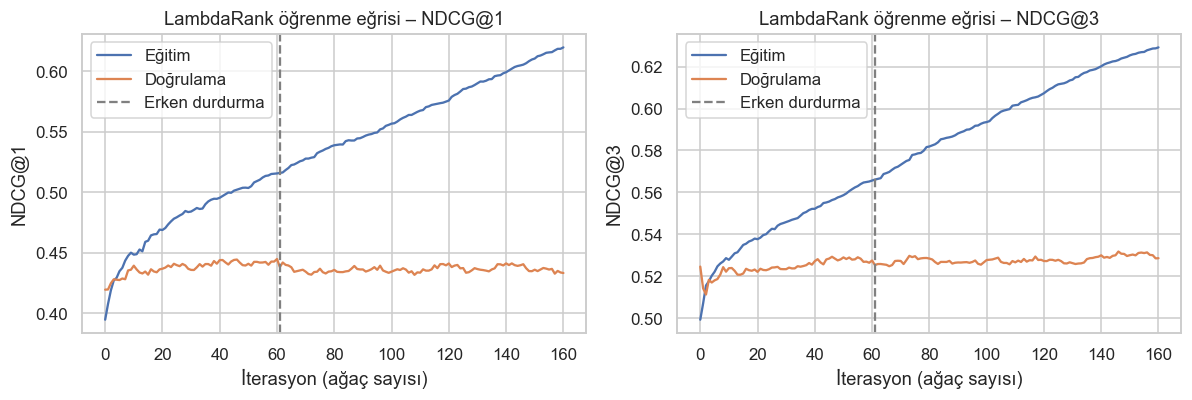

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, k in zip(axes, ["ndcg@1", "ndcg@3"]):
    ax.plot(ranker_evals["eğitim"][k], label="Eğitim")
    ax.plot(ranker_evals["doğrulama"][k], label="Doğrulama")
    ax.axvline(ranker.best_iteration_, ls="--", c="gray", label="Erken durdurma")
    ax.set(title=f"LambdaRank öğrenme eğrisi – {k.upper()}", xlabel="İterasyon (ağaç sayısı)",
           ylabel=k.upper())
    ax.legend()
savefig("lgbm_learning_curve")

### 7.5 Ablasyon: Ganyan oranı olmadan
Ganyan oranı piyasanın "kolektif tahmini"dir. Modelin oran bilgisi olmadan, yalnızca at/jokey/
antrenör geçmişi ve yarış koşullarıyla ne kadar başarılı olduğunu görmek için aynı LambdaRank
modeli oran özellikleri çıkarılarak yeniden eğitilir.

In [17]:
ranker_no_odds, _ = train_ranker(NUM_BASE, verbose=False)
test["score_lgbm_no_odds"] = ranker_no_odds.predict(test[NUM_BASE + CAT_COLS],
                                                    num_iteration=ranker_no_odds.best_iteration_)
r, preds["LambdaRank (oransız)"] = evaluate(test, "score_lgbm_no_odds", "LambdaRank (oransız)")
results.append(r)

## 8. Model Değerlendirme ve Karşılaştırma (Test Seti)

In [18]:
res_df = pd.DataFrame(results).set_index("Model")
res_df.round(3).to_csv(os.path.join(FIG_DIR, "model_results.csv"))
res_df.style.format("{:.3f}").highlight_max(
    axis=0, subset=[c for c in res_df.columns if "MAE" not in c and "RMSE" not in c],
    color="#c7e9c0")

,Kazanan isabeti,Top-3 isabeti,Exacta,NDCG@3,Spearman ρ,MAE (sıra),RMSE (sıra),Precision (kazanır),Recall (kazanır),F1 (kazanır),Accuracy (at bazında),ROC-AUC
Model,,,,,,,,,,,,
Rastgele,0.073,0.234,0.006,0.240,-0.005,4.217,5.205,0.073,0.073,0.073,0.852,0.502
Piyasa favorisi,0.306,0.503,0.069,0.550,0.489,2.806,3.692,0.306,0.306,0.306,0.889,0.786
Logistic Regression,0.297,0.495,0.070,0.544,0.489,2.815,3.694,0.297,0.297,0.297,0.888,0.783
Random Forest,0.287,0.498,0.061,0.540,0.492,2.796,3.680,0.287,0.287,0.287,0.886,0.783
LightGBM LambdaRank,0.288,0.499,0.057,0.544,0.488,2.814,3.699,0.288,0.288,0.288,0.886,0.786
LambdaRank (oransız),0.240,0.442,0.044,0.480,0.407,3.072,3.973,0.240,0.240,0.240,0.879,0.725


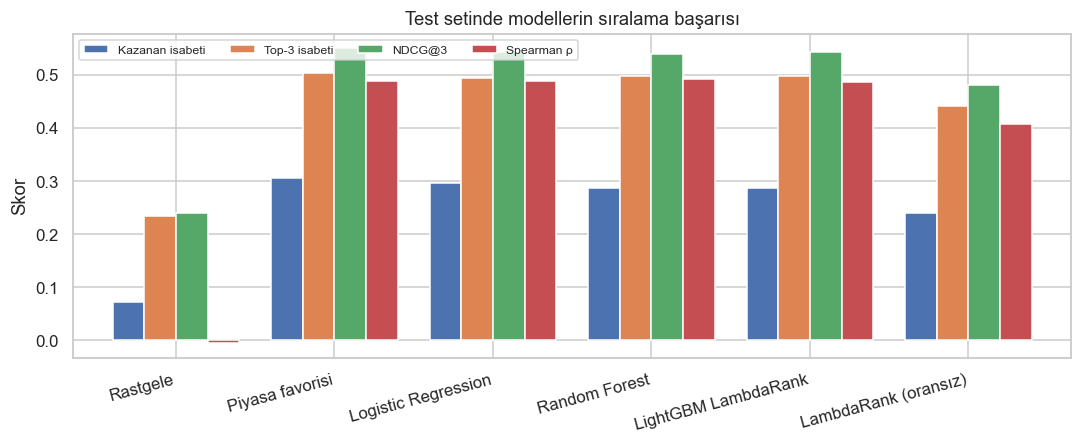

In [19]:
plot_cols = ["Kazanan isabeti", "Top-3 isabeti", "NDCG@3", "Spearman ρ"]
ax = res_df[plot_cols].plot(kind="bar", figsize=(10, 4.2), width=0.8)
ax.set(title="Test setinde modellerin sıralama başarısı", ylabel="Skor", xlabel="")
plt.xticks(rotation=15, ha="right")
ax.legend(loc="upper left", ncol=4, fontsize=8)
savefig("model_comparison")

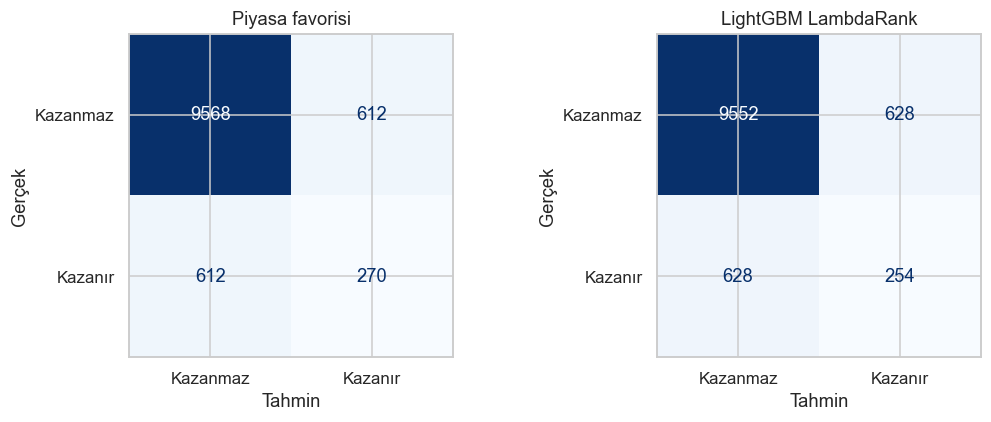

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Piyasa favorisi", "LightGBM LambdaRank"]):
    p = preds[name]
    cm = confusion_matrix(p["won"], p["pred_win"])
    ConfusionMatrixDisplay(cm, display_labels=["Kazanmaz", "Kazanır"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek")
savefig("confusion_matrices")

**Not:** Her yarışta tam olarak bir at "Kazanır" olarak tahmin edildiği için precision, recall ve
kazanan isabeti birbirine eşittir; at bazında *accuracy* ise "Kazanmaz" sınıfının baskınlığı
nedeniyle yüksek görünür ve tek başına yanıltıcıdır.

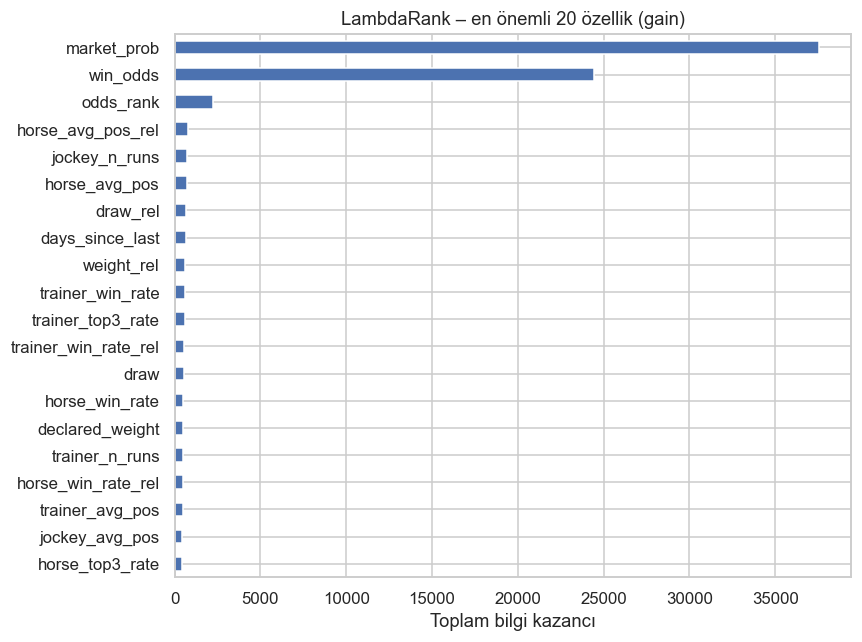

In [21]:
imp = pd.Series(ranker.booster_.feature_importance(importance_type="gain"),
                index=ranker.booster_.feature_name()).sort_values(ascending=True).tail(20)
plt.figure(figsize=(8, 6))
imp.plot(kind="barh", color="#4C72B0")
plt.title("LambdaRank – en önemli 20 özellik (gain)")
plt.xlabel("Toplam bilgi kazancı")
savefig("feature_importance")

### 8.1 Bahis simülasyonu (ek analiz)
Her test yarışında modelin 1. sıraya koyduğu ata 1 birim ganyan bahsi yapılsaydı getiri ne olurdu?
(HK'de `win_odds` yatırılan 1 birim dahil toplam ödemeyi gösterir.)

In [22]:
roi_rows = []
for name in ["Piyasa favorisi", "Logistic Regression", "Random Forest", "LightGBM LambdaRank",
             "LambdaRank (oransız)"]:
    p = preds[name]
    picks = p[p["pred_rank"] == 1]
    ret = (picks["won"] * picks["win_odds"]).sum()
    roi_rows.append({"Model": name, "Bahis sayısı": len(picks), "Kazanan": int(picks["won"].sum()),
                     "Toplam dönüş": round(ret, 1), "ROI": ret / len(picks) - 1})
roi_df = pd.DataFrame(roi_rows).set_index("Model")
roi_df.to_csv(os.path.join(FIG_DIR, "betting_roi.csv"))
roi_df.style.format({"ROI": "{:+.1%}", "Toplam dönüş": "{:.1f}"})

,Bahis sayısı,Kazanan,Toplam dönüş,ROI
Model,,,,
Piyasa favorisi,882,270,785.6,-10.9%
Logistic Regression,882,262,760.2,-13.8%
Random Forest,882,253,730.4,-17.2%
LightGBM LambdaRank,882,254,736.7,-16.5%
LambdaRank (oransız),882,212,751.4,-14.8%


## 9. Hata Analizi
Modelin hangi tür yarışlarda zorlandığını görmek için kazanan isabeti farklı kırılımlarda incelenir.

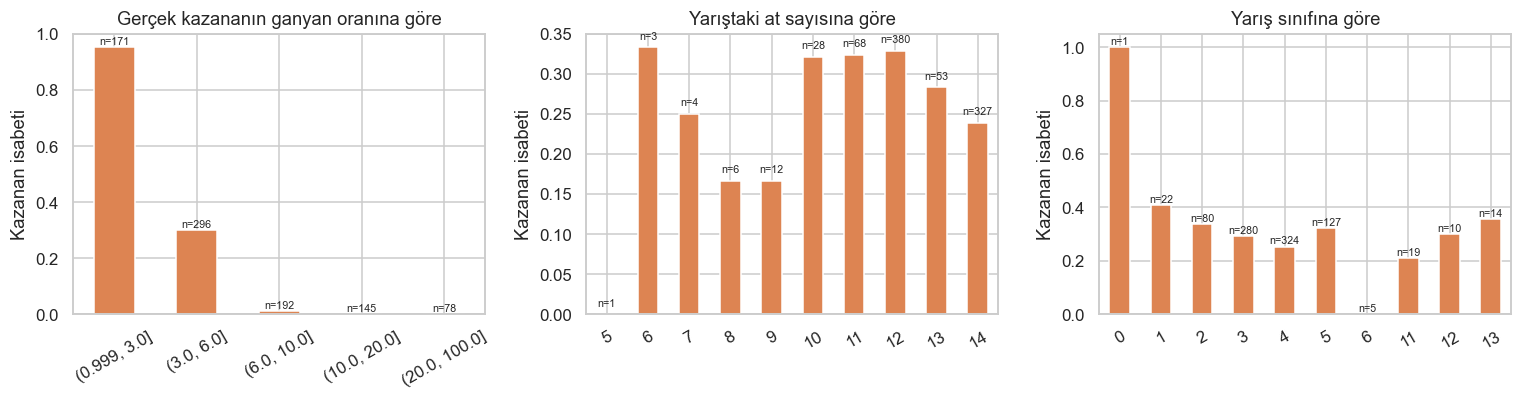

Sürpriz kazananların (oran > 10) payı: %25.3


In [23]:
p = preds["LightGBM LambdaRank"].copy()
race_level = p[p["pred_rank"] == 1][["race_id", "won", "field_size", "race_class", "distance",
                                     "going", "surface", "venue"]].rename(columns={"won": "hit"})
winners = p[p["result"] == 1][["race_id", "win_odds", "odds_rank"]].rename(
    columns={"win_odds": "winner_odds", "odds_rank": "winner_odds_rank"})
race_level = race_level.merge(winners, on="race_id")
race_level["Kazananın oranı"] = pd.cut(race_level["winner_odds"], [1, 3, 6, 10, 20, 100],
                                       include_lowest=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in [(axes[0], "Kazananın oranı", "Gerçek kazananın ganyan oranına göre"),
                       (axes[1], "field_size", "Yarıştaki at sayısına göre"),
                       (axes[2], "race_class", "Yarış sınıfına göre")]:
    gg = race_level.groupby(col, observed=True)["hit"].agg(["mean", "size"])
    gg["mean"].plot(kind="bar", ax=ax, color="#DD8452")
    for i, (m, s) in enumerate(zip(gg["mean"], gg["size"])):
        ax.text(i, m + 0.01, f"n={s}", ha="center", fontsize=7)
    ax.set(title=title, ylabel="Kazanan isabeti", xlabel="")
    ax.tick_params(axis="x", rotation=30)
savefig("error_analysis")
print("Sürpriz kazananların (oran > 10) payı: "
      f"%{(race_level['winner_odds'] > 10).mean() * 100:.1f}")

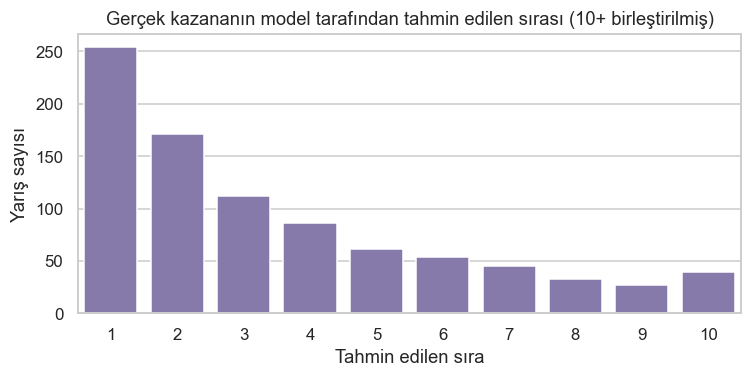

In [24]:
# Modelin kazananı kaçırdığı durumlarda gerçek kazananı kaçıncı sıraya koyduğu
miss = p[(p["result"] == 1)]
plt.figure(figsize=(7, 3.6))
sns.countplot(x=miss["pred_rank"].astype(int).clip(upper=10), color="#8172B2")
plt.title("Gerçek kazananın model tarafından tahmin edilen sırası (10+ birleştirilmiş)")
plt.xlabel("Tahmin edilen sıra"); plt.ylabel("Yarış sayısı")
savefig("winner_pred_rank")

### 9.1 Örnek yarış: tahmin edilen ve gerçek sıralama

In [25]:
example_id = p["race_id"].iloc[len(p) // 2]
ex = p[p["race_id"] == example_id].sort_values("pred_rank")[
    ["horse_no", "horse_id", "jockey_id", "horse_rating", "draw", "win_odds", "pred_rank", "result"]]
ex.columns = ["At no", "At ID", "Jokey ID", "Puan", "Kulvar", "Ganyan", "Tahmin sırası",
              "Gerçek sıra"]
print("Yarış ID:", example_id)
ex.astype({"Tahmin sırası": int}).reset_index(drop=True)

Yarış ID: 5905


,At no,At ID,Jokey ID,Puan,Kulvar,Ganyan,Tahmin sırası,Gerçek sıra
0,14,16,10,81,3,3.9,1,5
1,7,160,95,88,4,4.3,2,3
2,2,2860,157,90,12,5.7,3,13
3,8,2145,50,86,14,8.3,4,9
4,3,1698,96,92,6,9.2,5,2
5,5,1981,64,80,2,9.6,6,1
6,1,309,18,97,13,13.0,7,6
7,12,987,76,84,5,22.0,8,11
8,10,2202,21,85,8,25.0,9,10
9,9,1056,110,88,10,44.0,10,4


## 10. Sonuç
Sonuçların yorumu, güçlü/zayıf yönler ve geliştirme önerileri proje raporunda tartışılmıştır.